# 03 · EDA: structure of the corpus

**Needs:** the merged files from notebook 02. **Produces:** nothing.

Questions for this notebook:
1. How is the corpus spread across **sectors and fields**?
2. How is it spread over **time**?
3. Which **patent offices** do the documents come from?
4. Which **document types** (kind codes) are in the data?
5. Which patents were selected for **more than one field**?

Reminder: the sample is balanced by field (2,000 each). Any other distribution we see here is a property of the data,
not of the sampling. Equal quotas also mean we **cannot** say how frequent a technology is among all patents.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROC = Path("../data/processed")
by_field = pd.read_parquet(PROC / "patents_2021-2026_by_field.parquet")
by_pub = pd.read_parquet(PROC / "patents_2021-2026_by_publication.parquet")

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

# one colour per sector, used in every plot
SECTORS = ["Electrical engineering", "Instruments", "Chemistry", "Mechanical engineering"]
COLORS = dict(zip(SECTORS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))

# a readable label for each field, e.g. "06 Computer technology"
by_field["field"] = by_field["wipo_field_number"].astype(str).str.zfill(2) + " " + by_field["wipo_field_name"]
field_order = sorted(by_field["field"].unique())
field_sector = by_field.drop_duplicates("field").set_index("field")["wipo_sector"]

print(by_field.shape, by_pub.shape)

(64000, 25) (63968, 24)


## 1. Sectors and fields

Each sector has a different number of fields, so sectors have different numbers of rows.

In [2]:
sector_table = by_field.groupby("wipo_sector").agg(
    fields=("wipo_field_number", "nunique"),
    rows=("publication_number", "size"),
    distinct_publications=("publication_number", "nunique"),
).loc[SECTORS]
sector_table

,fields,rows,distinct_publications
wipo_sector,,,
Electrical engineering,8,16000,15997
Instruments,5,10000,10000
Chemistry,11,22000,21986
Mechanical engineering,8,16000,15999


## 2. Time

Publications per year and sector. 2026 stops in September, and the data for the latest months is still incomplete.

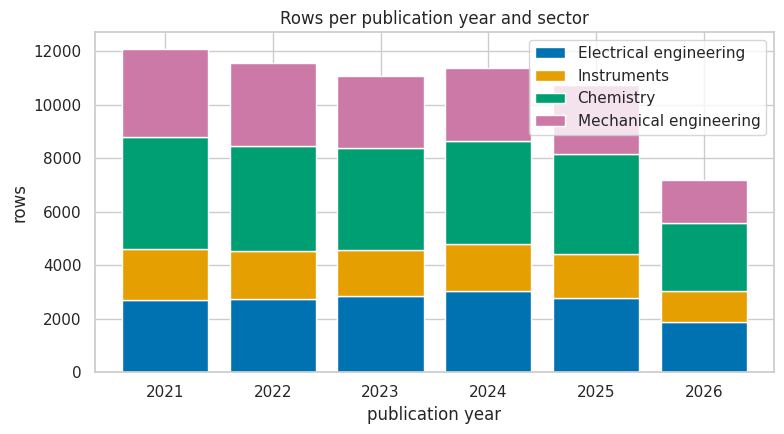

In [3]:
by_year = pd.crosstab(by_field["publication_year"], by_field["wipo_sector"])[SECTORS]

ax = by_year.plot.bar(stacked=True, color=[COLORS[s] for s in SECTORS], figsize=(8, 4.5), width=0.8)
ax.set_xlabel("publication year")
ax.set_ylabel("rows")
ax.set_title("Rows per publication year and sector")
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Is the time profile the same for all fields? For each field, the share of its 2,000 publications in each year:

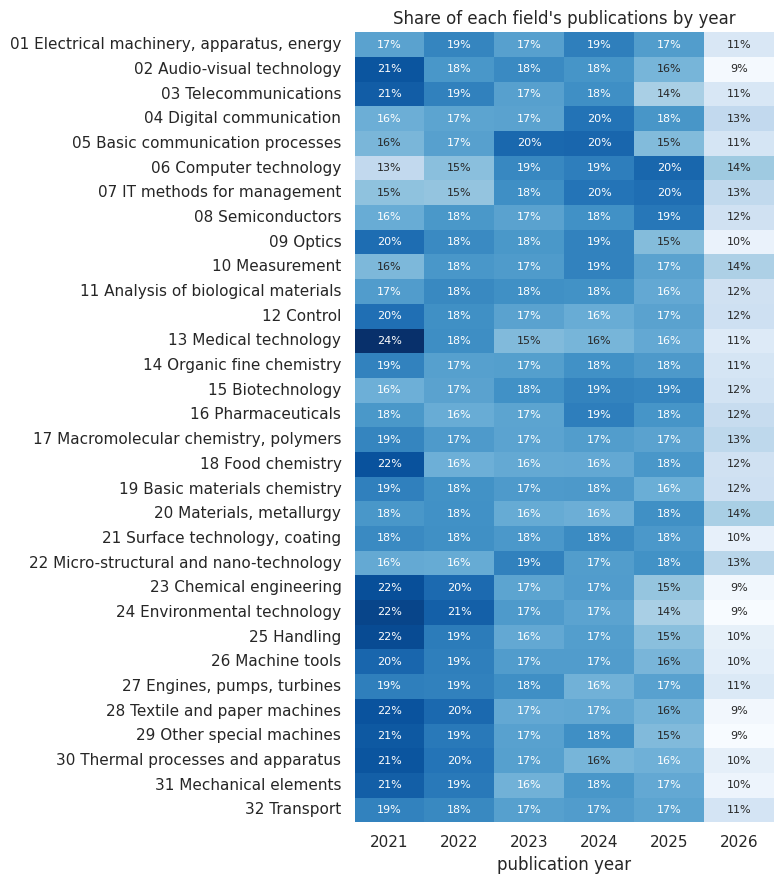

In [4]:
year_share = pd.crosstab(by_field["field"], by_field["publication_year"], normalize="index").loc[field_order]

fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(year_share, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8})
ax.set_ylabel("")
ax.set_xlabel("publication year")
ax.set_title("Share of each field's publications by year")
plt.tight_layout()
plt.show()

## 3. Patent offices

The office is the first part of the publication number (`CN`, `US`, `WO`, `EP`...). `WO` is the international PCT route and `EP` the European Patent Office.
We count **distinct publications** here.

In [5]:
office_counts = by_pub["office"].value_counts()
office_table = pd.DataFrame({"publications": office_counts, "share": office_counts / office_counts.sum()})
office_table.head(12).style.format({"share": "{:.1%}"})

,publications,share
office,,
CN,43389,67.8%
US,8621,13.5%
WO,3137,4.9%
EP,2055,3.2%
JP,1977,3.1%
KR,1628,2.5%
TW,1077,1.7%
AU,714,1.1%
CA,485,0.8%


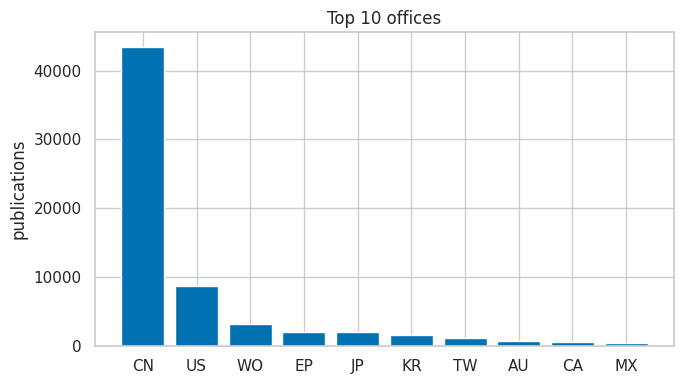

37 offices in total; the top 5 cover 93% of publications


In [6]:
top = office_table.head(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(top.index, top["publications"], color="#0072B2")
ax.set_ylabel("publications")
ax.set_title("Top 10 offices")
plt.tight_layout()
plt.show()

print(f"{office_table.shape[0]} offices in total; the top 5 cover {office_table['share'].head(5).sum():.0%} of publications")

One office dominates. Does it dominate **every** field? Share of each field's rows by office:

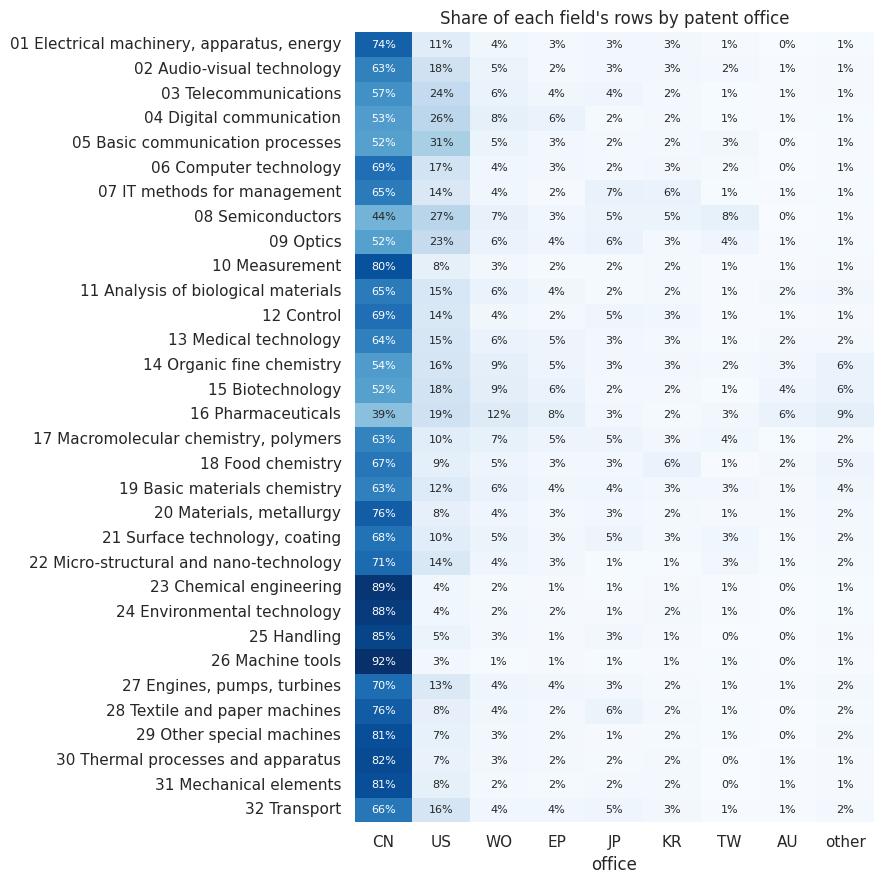

In [7]:
main_offices = ["CN", "US", "WO", "EP", "JP", "KR", "TW", "AU"]
office_group = by_field["office"].where(by_field["office"].isin(main_offices), "other")
office_share = pd.crosstab(by_field["field"], office_group, normalize="index").loc[field_order, main_offices + ["other"]]

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(office_share, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8})
ax.set_ylabel("")
ax.set_xlabel("office")
ax.set_title("Share of each field's rows by patent office")
plt.tight_layout()
plt.show()

The share of Chinese publications by field, ordered:

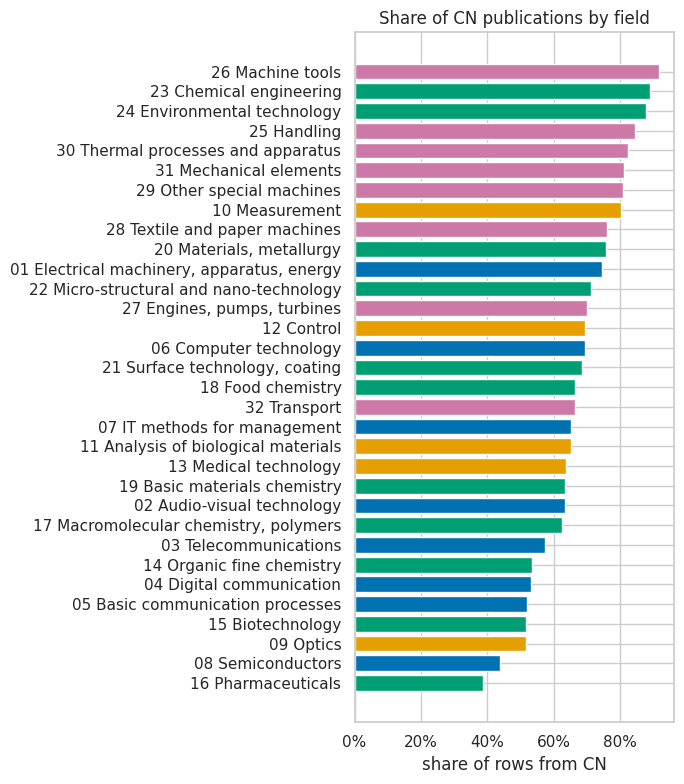

In [8]:
cn_share = (by_field["office"].eq("CN").groupby(by_field["field"]).mean().sort_values())
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(cn_share.index, cn_share.values, color=[COLORS[field_sector[f]] for f in cn_share.index])
ax.set_xlabel("share of rows from CN")
ax.set_title("Share of CN publications by field")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout()
plt.show()

## 4. Document types (kind codes)

The kind code is the last part of the publication number (`A1`, `B2`, `U`...).
**Its meaning depends on the office.** As a rough guide: `A` / `A1` are usually applications, `B` / `B1` / `B2` granted patents,
`U` utility models (a lighter form of protection that exists in China and a few other countries).

In [9]:
kind_counts = by_pub["kind_code"].value_counts()
kind_table = pd.DataFrame({"publications": kind_counts, "share": kind_counts / kind_counts.sum()})
kind_table.head(10).style.format({"share": "{:.1%}"})

,publications,share
kind_code,,
A,23589,36.9%
U,15253,23.8%
A1,10051,15.7%
B,9478,14.8%
B2,3964,6.2%
B1,689,1.1%
A3,234,0.4%
A2,220,0.3%
C,210,0.3%


In [10]:
# kind codes by office: which office uses which code?
top_kinds = kind_counts.head(8).index
ct = pd.crosstab(by_pub["office"], by_pub["kind_code"])
ct.loc[office_counts.head(8).index, top_kinds]

kind_code,A,U,A1,B,B2,B1,A3,A2
office,,,,,,,,
CN,19147,15221,0,9014,0,0,0,0
US,0,0,4582,0,3737,262,0,3
WO,0,0,2894,0,0,0,117,69
EP,0,0,1806,0,0,0,113,134
JP,1977,0,0,0,0,0,0,0
KR,1295,0,0,0,0,333,0,0
TW,686,20,0,371,0,0,0,0
AU,0,0,429,0,227,1,0,2


Share of kind codes starting with `U` (utility models, mostly) by field:

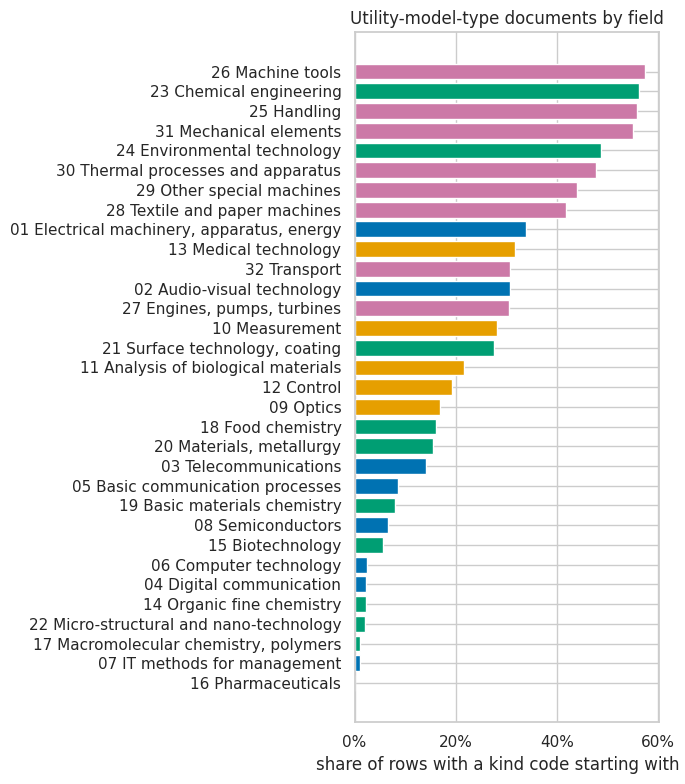

In [11]:
u_share = by_field["kind_code"].str.startswith("U").groupby(by_field["field"]).mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(u_share.index, u_share.values, color=[COLORS[field_sector[f]] for f in u_share.index])
ax.set_xlabel("share of rows with a kind code starting with U")
ax.set_title("Utility-model-type documents by field")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout()
plt.show()

## 5. Publications selected for more than one field

A publication is selected **per field**, so one that fits two fields can be drawn twice.
It happens rarely. Notebook 05 measures how many publications *could* have been selected for several fields.

In [12]:
multi = by_pub[by_pub["n_fields"] > 1]
print(len(multi), "publications selected for two fields")
pairs = multi["wipo_field_names"].map(lambda names: " + ".join(names)).value_counts()
pairs

32 publications selected for two fields


wipo_field_names
Biotechnology + Food chemistry                                               2
Semiconductors + Micro-structural and nano-technology                        2
Measurement + Mechanical elements                                            1
Optics + Organic fine chemistry                                              1
Pharmaceuticals + Basic materials chemistry                                  1
Analysis of biological materials + Environmental technology                  1
Environmental technology + Engines, pumps, turbines                          1
Telecommunications + Basic communication processes                           1
Computer technology + Control                                                1
Surface technology, coating + Chemical engineering                           1
Organic fine chemistry + Basic materials chemistry                           1
Organic fine chemistry + Pharmaceuticals                                     1
Biotechnology + Chemical engineerin

## What to take away

- Fields are balanced by construction; sectors are not, because they contain different numbers of fields.
- Years: 2021–2025 are similar in size; 2026 is incomplete.
- The corpus is **not balanced geographically**: China has about two thirds of the documents, and its weight changes a lot from one field to another:
  below 40% in Pharmaceuticals, above 90% in Machine tools.
  Mechanical and chemical-engineering fields are the most Chinese; Telecommunications, Digital communication and Semiconductors have the largest US share.
- Document types are mixed, and kind codes differ across offices: the same code does not mean the same thing in the US and in China.
  Utility models (kind code `U`) appear only for a few offices, almost all in China.
  Any comparison between "granted" and "not granted" needs care.

## Try it yourself

1. Which field has the largest share of US publications? Which the smallest?
2. Make the year heatmap using only granted-type documents (kind code starting with `B`). What changes?
3. How many publications are from offices outside the top 10?